
### HDN noise-model calibration with LISAI

This notebook demonstrates how to generate an experimental noise model for **unsupervised HDN training**, using paired high- and low-SNR RESOLFT images from the `vim_fixed_multi_snr` dataset, available on [Zenodo](https://doi.org/10.5281/zenodo.22877255).

The goal is to estimate the conditional noise distribution, $p(\mathrm{observation}\mid\mathrm{signal})$, and fit a **Gaussian Mixture Model (GMM)**. The resulting calibration can then be reused for HDN training.

**Workflow:**
1. Load and visualize paired reference and noisy images.
2. Fit the noise model using LISAI's public NumPy API.
3. Inspect the empirical histogram and fitted GMM.
4. Save the calibration in the LISAI workspace.

A standalone version is available in [`scripts/generate_noise_model.py`](../scripts/generate_noise_model.py).

**Scientific references:** The experimental noise-model approach originates from [Probabilistic Noise2Void](https://doi.org/10.3389/fcomp.2020.00005) (Krull et al., 2020), with GMM parameterization developed in [Fully Unsupervised Probabilistic Noise2Void](https://doi.org/10.1109/ISBI45749.2020.9098612) (Prakash et al., 2020).


### Before starting: choosing calibration data

Noise-model calibration requires **paired images of the same stationary sample**:

- **Signal:** a high-SNR reference, ideally obtained by averaging several aligned acquisitions.
- **Observation:** the corresponding noisy image, acquired under conditions representative of HDN training.

Images must be **pixel-aligned** and use the same processing and intensity conventions. For MoNaLISA, calibrate on reconstructed images if HDN will train on reconstructed data.

**Input:** two TIFF files (`YX` or `NYX`) or two folders with matching TIFF filenames. Reference averaging and noise-level selection must be performed beforehand.

**Requirements:** an initialized LISAI workspace and a Python environment with LISAI's full dependencies (`pip install -e ".[full]"`).

## 1. Imports

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm
import numpy as np
import tifffile
from IPython.display import Image, display

from lisai.config.settings import Settings
from lisai.noise_models import NoiseModelOptions, create_noise_model

## 2. Parameters — edit this cell

These are the main controls you will normally adjust. The defaults follow the existing LISAI noise-model fitter; uncommon GMM settings (`gmm_n_coeff`, `gmm_min_sigma`, `gmm_batch_size`, etc.) are intentionally left at their library defaults.

**Normalization:** `NORM_SIGNAL_TO_OBSERVATION` matches the reference's overall statistics to noisy measurements before fitting. `NORMALIZE_EVERYTHING` applies the fitter's usual standardization. LISAI saves the required statistics in `norm_prm.json` so HDN can interpret the calibration correctly.

**Model complexity:** more histogram bins require more representative pixel pairs; more Gaussian components increase flexibility but can overfit. Use fewer epochs only to check that the workflow runs, not as a scientifically validated model.

In [ ]:
# ── Paths and model identity ──────────────────────────────────────────────────
WORKSPACE = Path(r"E:\LISAI") # Existing initialized LISAI workspace
SIGNAL_SOURCE = WORKSPACE / r"datasets\training\vim_fixed_multi_snr\preprocess\recon\gt_avg\train" # High-SNR reference TIFF or folder
OBSERVATION_SOURCE = WORKSPACE / r"E:\lisai\datasets\training\vim_fixed_multi_snr\preprocess\recon\inp_single\train" # Matching noisy TIFF or folder
MODEL_NAME = "example_vimentin_notebook" # Name used later in HDN training

# ── Execution / safety ────────────────────────────────────────────────────────
DEVICE = "auto"               # "auto" (CUDA if available), "cuda", or "cpu"
OVERWRITE = False             # True replaces a previous calibration of this name
SAVE_GMM_PLOTS = True         # Save the model's diagnostic GMM_plot.png and .svg

# ── Data preparation ──────────────────────────────────────────────────────────
NORM_SIGNAL_TO_OBSERVATION = True  # Match high-SNR reference statistics to noisy data
NORMALIZE_EVERYTHING = True        # Standardize data for the histogram/GMM fit
CLIP = -3.0                        # Clip values below this BEFORE normalization; None disables
CROP_SIZE = None                   # Optional center crop, e.g. (512, 512) in (Y, X)

# ── Empirical histogram and GMM fitting ───────────────────────────────────────
HISTOGRAM_BINS = 256       # Resolution of p(observation | signal) histogram
GMM_N_GAUSSIAN = 5        # Number of Gaussian components per signal intensity
GMM_N_EPOCHS = 3000       # Optimization epochs; e.g. 100 only for a quick code test
GMM_LEARNING_RATE = 0.05  # GMM optimization learning rate

# ── Notebook visualization only (does not affect the fitted model) ────────────
PREVIEW_PAIR_INDEX = 0    # Which paired image to display before fitting

## 3. Load the matching TIFF images

The helper below keeps the example **self-contained**: no command-line arguments and no dependence on Jupyter's working directory. It accepts a TIFF file on each side, or a directory on each side.

- Single `(Y, X)` TIFFs become stacks with `N=1`.
- Matching `(N, Y, X)` TIFF stacks contribute `N` pairs.
- Directories must contain the **same relative TIFF filenames**. Every pair and all images must have the same spatial dimensions.

**Note:** matching filenames and shapes do not guarantee biological correspondence. Check the actual pairs visually in the following cell.

In [11]:
def tiff_files(source: Path) -> dict[str, Path]:
    '''List TIFF inputs by relative filename, or select one TIFF file.'''
    if source.is_file():
        if source.suffix.lower() not in {".tif", ".tiff"}:
            raise ValueError(f"Expected a TIFF file: {source}")
        return {"__single__": source}
    if not source.is_dir():
        raise FileNotFoundError(f"Input source does not exist: {source}")

    files = {
        p.relative_to(source).as_posix(): p
        for p in source.rglob("*")
        if p.is_file() and p.suffix.lower() in {".tif", ".tiff"}
    }
    if not files:
        raise ValueError(f"No TIFF files found in {source}")
    return files


def load_paired_tiffs(signal_source: Path, observation_source: Path):
    '''Load aligned YX images / NYX stacks as two arrays shaped (N, Y, X).'''
    if signal_source.is_file() != observation_source.is_file():
        raise ValueError("Supply two TIFF files or two directories, not one of each")

    signals = tiff_files(signal_source)
    observations = tiff_files(observation_source)
    if signals.keys() != observations.keys():
        raise ValueError(
            "Signal/observation filenames differ. "
            f"Missing noisy files: {sorted(signals.keys() - observations.keys())[:5]}; "
            f"missing reference files: {sorted(observations.keys() - signals.keys())[:5]}"
        )

    reference_parts, noisy_parts = [], []
    expected_yx = None
    for filename in sorted(signals):
        reference = np.asarray(tifffile.imread(signals[filename]), dtype=np.float32)
        noisy = np.asarray(tifffile.imread(observations[filename]), dtype=np.float32)
        if reference.shape != noisy.shape or reference.ndim not in (2, 3):
            raise ValueError(
                f"Invalid pair {filename}: reference {reference.shape}, "
                f"noisy {noisy.shape}; expected matching YX or NYX images"
            )
        if expected_yx is None:
            expected_yx = reference.shape[-2:]
        if reference.shape[-2:] != expected_yx:
            raise ValueError(f"Spatial dimensions differ in {filename}")

        reference_parts.append(reference[None] if reference.ndim == 2 else reference)
        noisy_parts.append(noisy[None] if noisy.ndim == 2 else noisy)

    return np.concatenate(reference_parts), np.concatenate(noisy_parts)

In [12]:
signal, observation = load_paired_tiffs(SIGNAL_SOURCE, OBSERVATION_SOURCE)

print(f"Loaded {signal.shape[0]} matched image pairs")
print(f"Reference shape: {signal.shape}, noisy shape: {observation.shape}")
print(f"Reference intensities: {signal.min():.3g} to {signal.max():.3g}")
print(f"Noisy intensities:     {observation.min():.3g} to {observation.max():.3g}")

assert signal.shape == observation.shape
assert np.isfinite(signal).all() and np.isfinite(observation).all()

Loaded 21 matched image pairs
Reference shape: (21, 1200, 1200), noisy shape: (21, 1200, 1200)
Reference intensities: -323 to 1.78e+03
Noisy intensities:     -417 to 1.42e+03


## 4. Visually verify a representative image pair

Before calibrating, inspect at least a few pairs. Both panels below use **the same intensity display range**. The reference and observation should depict the *same structures* and have no systematic spatial shift. A difference in overall intensity or random fluctuations is expected; changes in structure are not.

You can change `PREVIEW_PAIR_INDEX` in the parameter cell and re-run this plot.

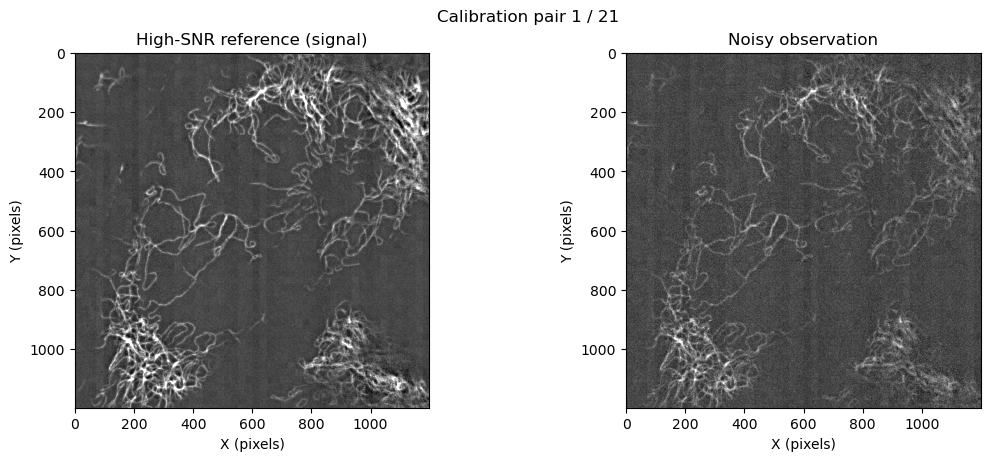

In [13]:
if not 0 <= PREVIEW_PAIR_INDEX < signal.shape[0]:
    raise IndexError(f"PREVIEW_PAIR_INDEX must be between 0 and {signal.shape[0] - 1}")

reference = signal[PREVIEW_PAIR_INDEX]
noisy = observation[PREVIEW_PAIR_INDEX]
low = min(np.percentile(reference, 1), np.percentile(noisy, 1))
high = max(np.percentile(reference, 99.5), np.percentile(noisy, 99.5))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
for ax, image, label in zip(
    axes, (reference, noisy), ("High-SNR reference (signal)", "Noisy observation")
):
    ax.imshow(image, cmap="gray", vmin=low, vmax=high)
    ax.set_title(label)
    ax.set_xlabel("X (pixels)")
    ax.set_ylabel("Y (pixels)")
fig.suptitle(f"Calibration pair {PREVIEW_PAIR_INDEX + 1} / {len(signal)}")
plt.show()

## 5. Fit and save the noise model

`create_noise_model()` now performs the tasks that were separate manual cells in the old notebook:

1. Applies the configured clipping/cropping and calibration normalization.
2. Estimates the empirical conditional histogram of noisy values versus reference intensities.
3. Fits a signal-dependent Gaussian mixture model to that conditional distribution.
4. Saves the model, normalization statistics, histogram, information file, and optional diagnostic plots.

The **public array API** does not need a registered LISAI dataset, intermediate TIFF files or direct calls into the internal HDN classes. `Settings.from_workspace()` selects the persistent folder explicitly, independently of your CLI's selected workspace.

> If `MODEL_NAME` already exists, `OVERWRITE=False` intentionally raises `FileExistsError`. Change the name or deliberately set `OVERWRITE=True` if you want to replace the calibration.

In [14]:
settings = Settings.from_workspace(WORKSPACE)

options = NoiseModelOptions(
    norm_sig_to_obs=NORM_SIGNAL_TO_OBSERVATION,
    normalize_everything=NORMALIZE_EVERYTHING,
    clip=CLIP,
    crop_size=CROP_SIZE,
    histogram_bins=HISTOGRAM_BINS,
    gmm_n_gaussian=GMM_N_GAUSSIAN,
    gmm_n_epochs=GMM_N_EPOCHS,
    gmm_learning_rate=GMM_LEARNING_RATE,
    save_gmm_plot=SAVE_GMM_PLOTS,
)

result = create_noise_model(
    signal=signal,
    observation=observation,
    name=MODEL_NAME,
    settings=settings,
    options=options,
    device=DEVICE,
    overwrite=OVERWRITE,
)

print(f"Saved noise model '{result.name}' to:\n  {result.save_dir}")
print(f"Pairs used: {result.n_pairs}")
print(f"Fitted reference-signal range: {result.min_signal:.3g} to {result.max_signal:.3g}")

Histogram saved at: E:\lisai\noise_models\.example.staging-mrfb_i1f\Histogram.npy
0 1.4198750257492065
100 1.2328346967697144
200 1.2299567461013794
300 1.2282979488372803
400 1.2279438972473145
500 1.2290998697280884
600 1.2274190187454224
700 1.2265125513076782
800 1.2285362482070923
900 1.2260926961898804
1000 1.2255710363388062
1100 1.2258952856063843
1200 1.225871205329895
1300 1.2242228984832764
1400 1.2259047031402588
1500 1.2270801067352295
1600 1.2253375053405762
1700 1.224471092224121
1800 1.224678874015808
1900 1.2258292436599731
2000 1.2232213020324707
2100 1.2267292737960815
2200 1.223731279373169
2300 1.2234359979629517
2400 1.2230809926986694
2500 1.2251981496810913
2600 1.2258232831954956
2700 1.2245988845825195
2800 1.2223747968673706
2900 1.2248127460479736

The trained parameters (GMM) is saved at location: E:\lisai\noise_models\.example.staging-mrfb_i1f\
GMM saved at: E:\lisai\noise_models\.example.staging-mrfb_i1f\GMM.npz
Noise model saved at: E:\lisai\noise_models

## 6. Explore the empirical noise histogram

The saved Histogram.npy is a 3D numpy array:
- histogram[0] contains the empirical 2D conditional probability distribution, each row representing a reference signal-intensity bin, and each column represents a noisy observation-intensity bin.
- histogram[1] and histogram[2] store the lower and upper intensity boundaries of the histogram bins.
 

The color scaling below uses a fourth-root transformation **for visual contrast only**; it does not change the fitted model. The axes show intensities in the *fitting domain* (possibly normalized, depending on your options).

Saved histogram array shape: (3, 256, 256)


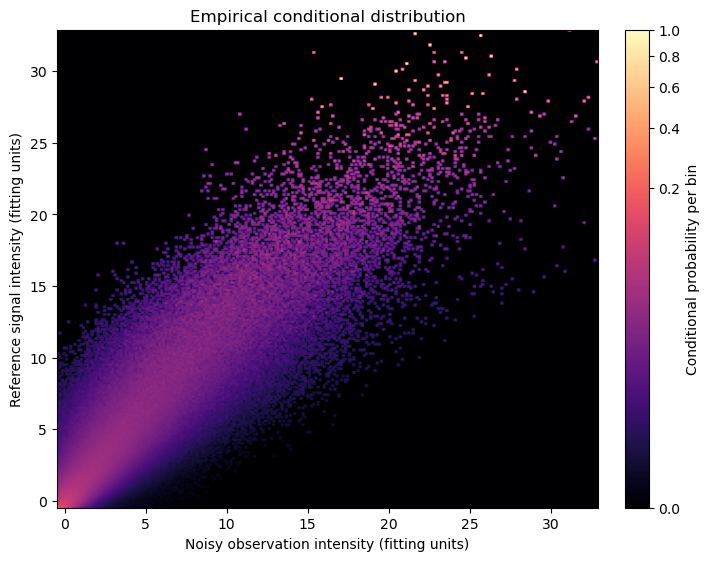

In [18]:
histogram = np.load(result.histogram_path)
print("Saved histogram array shape:", histogram.shape)

# Original LISAI histogram: first plane is p(observation | signal).
probability = histogram[0]
fit_min = float(np.min(histogram[1]))
fit_max = float(np.max(histogram[2]))

fig, ax = plt.subplots(figsize=(7, 5.5), constrained_layout=True)
image = ax.imshow(
    probability,
    origin="lower",
    extent=(fit_min, fit_max, fit_min, fit_max),
    cmap="magma",
    norm=PowerNorm(gamma=0.25),
    aspect="auto",
)
ax.set_xlabel("Noisy observation intensity (fitting units)")
ax.set_ylabel("Reference signal intensity (fitting units)")
ax.set_title("Empirical conditional distribution")
fig.colorbar(image, ax=ax, label="Conditional probability per bin")
plt.show()

## 7. Compare the fitted GMM with the empirical distribution

When `SAVE_GMM_PLOTS=True`, LISAI saves a figure comparing the conditional histogram to the fitted GMM at a selection of reference intensities. The notebook **displays the saved figure** rather than fitting a second model.

Look for a reasonable match between the model and empirical distributions across the signal range, particularly at low and high reference intensities. Sparse regions can give unreliable fits. A successful optimization or a plausible-looking curve is **not** sufficient scientific validation by itself.

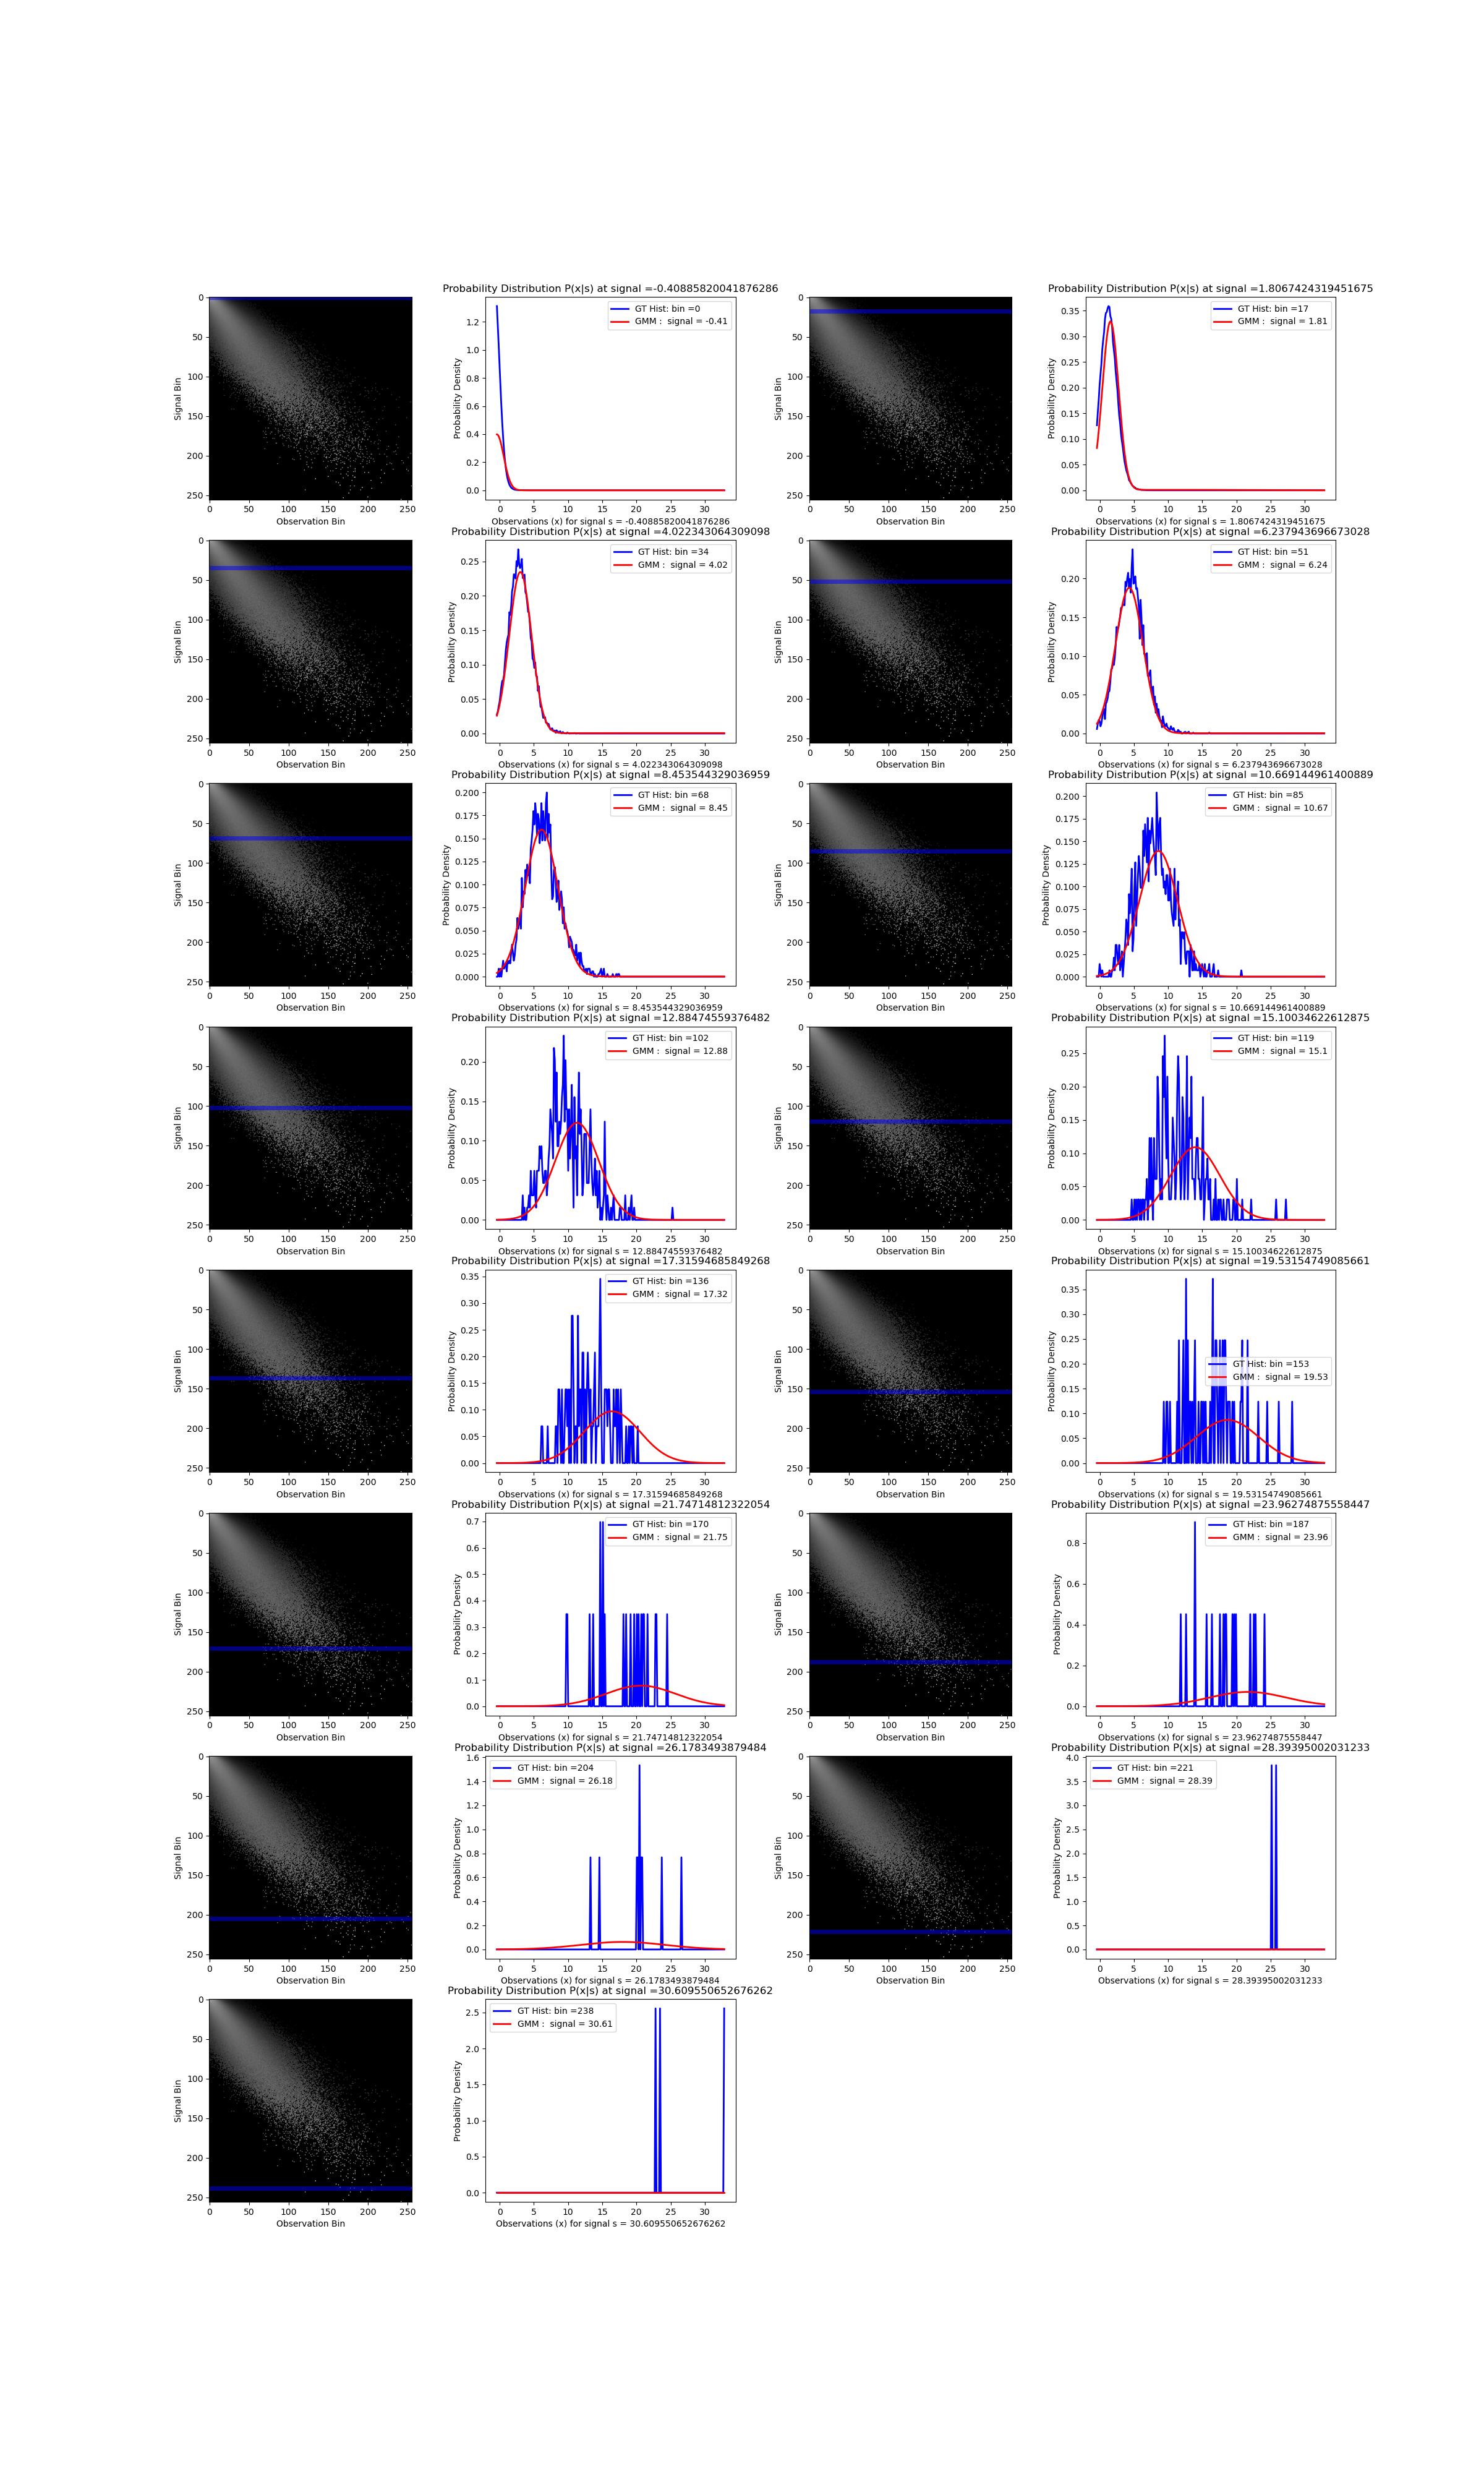

In [17]:
if result.gmm_plot_png_path is not None and result.gmm_plot_png_path.is_file():
    display(Image(filename=str(result.gmm_plot_png_path)))
else:
    print("GMM diagnostic plot was not saved. Set SAVE_GMM_PLOTS=True to generate it.")

## 8. Reuse the saved calibration for HDN training

The saved folder is in the selected workspace:

```text
<workspace>/noise_models/<model-name>/
    GMM.npz           # fitted conditional likelihood (HDN-compatible)
    norm_prm.json     # calibration clipping/normalization parameters
    Histogram.npy     # empirical conditional histogram
    info.txt          # fitting settings and summary
    GMM_plot.png      # optional diagnostic figure
    GMM_plot.svg      # optional diagnostic figure
```

The important value for quick unsupervised HDN training is **`result.name`**, not a full file path. The model name is resolved against the selected LISAI workspace. The actual noisy images used for unsupervised training need **not** have matching clean references; those pairs were needed only for calibration.

In [15]:
print("Calibration name for quick-HDN training:", result.name)
print("Saved files:")
for label, path in (
    ("GMM", result.gmm_path),
    ("Normalization", result.norm_prm_path),
    ("Histogram", result.histogram_path),
    ("Info", result.info_path),
    ("GMM PNG", result.gmm_plot_png_path),
    ("GMM SVG", result.gmm_plot_svg_path),
):
    if path is not None:
        print(f"  {label:14} {path}")

Calibration name for quick-HDN training: example
Saved files:
  GMM            E:\lisai\noise_models\example\GMM.npz
  Normalization  E:\lisai\noise_models\example\norm_prm.json
  Histogram      E:\lisai\noise_models\example\Histogram.npy
  Info           E:\lisai\noise_models\example\info.txt
  GMM PNG        E:\lisai\noise_models\example\GMM_plot.png
  GMM SVG        E:\lisai\noise_models\example\GMM_plot.svg


For example, after registering an **independent** noisy training dataset, the quick-HDN configuration can use the saved model:

```python
from lisai.training.quick_hdn import prepare_quick_hdn_training

preview = prepare_quick_hdn_training(
    settings=settings,
    dataset_name="my_registered_training_dataset",
    noise_model_name=result.name,
    experiment_name="hdn_first",
    epochs=20,
    patch_size=64,
)
print(preview.split_counts)
```

This is an **illustrative next step**, not executed in this calibration notebook. The training dataset must be registered and contain the independent recordings required by quick HDN; `prepare_quick_hdn_training()` prepares the run but does not train a network.